## Advanced Task: Robust Perception

In [ ]:
import numpy as np
import cv2

def add_dust(img, meters, seed=None, rate=6.0):
    """
    Simulates Dust on the camera lenase after you drove in the cave.
    img: RGB- or BGR-uint8-Bild (H, W, 3)
    Same seed + more Meter = same dust on the lense + more new onces.
    """
    if meters <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    h, w = img.shape[:2]
    diag = np.hypot(h, w)

    # Particle: Number is growing with the distance
    log_t = np.zeros((h, w), np.float32)                 
    for _ in range(rng.poisson(rate * meters)):
        x = rng.uniform(0, w)
        y = rng.beta(2.0, 1.3) * h                       # down it is hifher dichter
        r = min(0.005 * (1 - rng.uniform()) ** (-1 / 1.4), 0.08) * diag
        alpha = rng.uniform(0.3, 0.85)                   # how dense they are
        spot = np.zeros((h, w), np.float32)
        cv2.ellipse(spot, (int(x), int(y)),
                    (max(1, int(r)), max(1, int(r * rng.uniform(0.5, 1.0)))),
                    rng.uniform(0, 180), 0, 360, 1.0, -1, cv2.LINE_AA)
        log_t += spot * np.log(1 - alpha)                # overlap with image
    A = 1 - np.exp(log_t)

    # Blur because you have dust on the camera
    A = cv2.GaussianBlur(A, (0, 0), 0.006 * diag)[..., None]

    # They are light ocker 
    I = img.astype(np.float32)
    scatter = cv2.GaussianBlur(I, (0, 0), 0.04 * diag)
    dust = np.array([200, 160, 120], np.float32)          # RGB (bei BGR: [120, 160, 200])
    spot_col = 0.65 * dust + 0.35 * scatter
    out = I * (1 - A) + spot_col * A

    #Contrast reduction
    film = 0.5 * (1 - np.exp(-meters / 100))
    out = out * (1 - film) + film * (0.6 * scatter + 0.4 * dust)

    return np.clip(out, 0, 255).astype(np.uint8)

In [ ]:
import numpy as np

def add_darkness(img, level, seed=None):
    """
    Simulates Darkness in the image.
    img:   RGB- or BGR-uint8-Bild (H, W, 3)
    level: 0 = normal, 1 = very dark
    """
    if level <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    h, w = img.shape[:2]
    x = img.astype(np.float32) / 255.0

    # to the borders of the image darker (because of mars rover lights)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    rr = np.hypot((xx - w / 2) / (w / 2), (yy - h / 2) / (h / 2))
    vignette = 1 - 0.55 * level * np.clip(rr / 1.3, 0, 1) ** 2

    # less light
    exposure = 1 - 0.85 * level
    x = x * exposure * vignette[..., None]

    # Sensor noise
    full_well = 600.0
    x = rng.poisson(x * full_well).astype(np.float32) / full_well
    x = x + rng.normal(0, 0.004 + 0.01 * level, x.shape).astype(np.float32)

    # Auto Gain lights up the image, but we have therefore more noise
    gain = exposure ** -0.6
    return np.clip(x * gain * 255, 0, 255).astype(np.uint8)

## Same Setup as before

In [ ]:
# Setup
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

import json, glob, random, copy, time
import numpy as np
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.utils import draw_bounding_boxes
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchmetrics.detection import MeanAveragePrecision
from PIL import Image
import matplotlib.pyplot as plt

# Paths
DATA_DIR      = 'data/processed'
ANN_FILE      = os.path.join(DATA_DIR, '_annotations.coco.json')
NEG_TRAIN_DIR = 'data/negatives_train'
NEG_TEST_DIR  = 'data/negatives_test'
OUT_DIR       = 'runs'

# Training
SEED       = 42
EPOCHS     = 10
BATCH      = 2        
MODEL      = 'mobilenet'   
IMG_SIZE   = 608           
LR         = 0.005
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15
CONF       = 0.5      
PRETRAINED = True     

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')

DEVICE = torch.device('cpu')
print('Device:', DEVICE, '| torch', torch.__version__, '| torchvision', torchvision.__version__)

Device: cpu | torch 2.8.0 | torchvision 0.23.0


In [ ]:
coco = json.load(open(ANN_FILE))

# Roboflow legt eine Oberkategorie an (z. B. 'spacerobtics') -> ignorieren
super_names = {c['supercategory'] for c in coco['categories']}
class_names = sorted({c['name'] for c in coco['categories'] if c['name'] not in super_names})
NUM_CLASSES = len(class_names)

# COCO-Kategorie-ID -> unser Label (1..K, 0 ist Hintergrund)
name_to_label = {n: i + 1 for i, n in enumerate(class_names)}
cat_to_label = {c['id']: name_to_label[c['name']]
                for c in coco['categories'] if c['name'] in name_to_label}

# Pro Bild: Pfad, Boxen (x1,y1,x2,y2), Labels
records = {img['id']: {'path': os.path.join(DATA_DIR, img['file_name']),
                       'name': img['file_name'], 'boxes': [], 'labels': []}
           for img in coco['images']}
skipped = 0
for a in coco['annotations']:
    if a['category_id'] not in cat_to_label:
        skipped += 1
        continue
    x, y, w, h = a['bbox']
    if w < 1 or h < 1:
        skipped += 1
        continue
    r = records[a['image_id']]
    r['boxes'].append([x, y, x + w, y + h])
    r['labels'].append(cat_to_label[a['category_id']])
records = list(records.values())

missing = [r['path'] for r in records if not os.path.exists(r['path'])]
print(f'{len(records)} Images, {NUM_CLASSES} Classes, {skipped} Boxes skipped')
print(f'Missing Image Data: {len(missing)}')

counts = {n: 0 for n in class_names}
for r in records:
    for l in r['labels']:
        counts[class_names[l - 1]] += 1
for n, c in counts.items():
    print(f'  {n:<10} {c:>4} Boxen')

111 Bilder, 6 Klassen, 0 Boxen übersprungen
Fehlende Bilddateien: 0
  alien        23 Boxen
  ball         27 Boxen
  graffiti     53 Boxen
  mushroom     31 Boxen
  stone        43 Boxen
  stop         60 Boxen


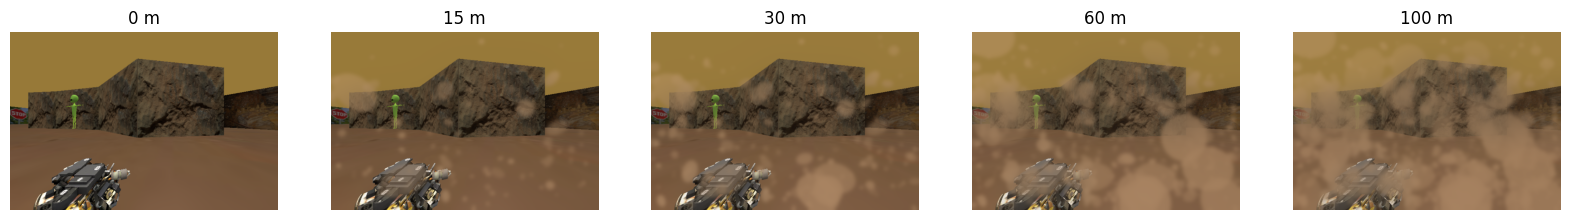

In [ ]:
r = records[0]
img = np.array(Image.open(r['path']).convert('RGB'))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, m in zip(axes, [0, 15, 30, 60, 100]):
    ax.imshow(add_dust(img, meters=m, seed=0))
    ax.set_title(f'{m} m'); ax.axis('off')
plt.show()

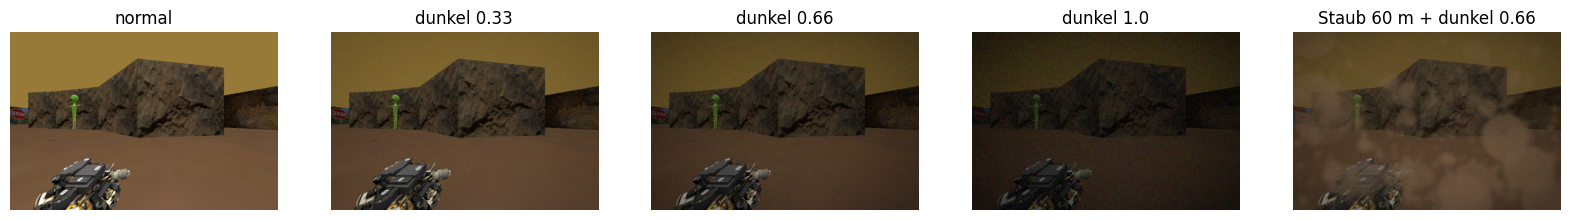

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
panels = [('normal', img),
          ('dark 0.33', add_darkness(img, 0.33, seed=0)),
          ('dark 0.66', add_darkness(img, 0.66, seed=0)),
          ('dark 1.0',  add_darkness(img, 1.0,  seed=0)),
          ('dust 60 m + dark 0.66', add_darkness(add_dust(img, 60, seed=0), 0.66, seed=0))]
for ax, (t, im) in zip(axes, panels):
    ax.imshow(im); ax.set_title(t); ax.axis('off')
plt.show()

## Train / Test / Validation

In [ ]:
rng = random.Random(SEED)
idx = list(range(len(records)))
rng.shuffle(idx)
n_test = round(len(idx) * TEST_FRAC)
n_val = round(len(idx) * VAL_FRAC)

test_records  = [records[i] for i in idx[:n_test]]
val_records   = [records[i] for i in idx[n_test:n_test + n_val]]
train_records = [records[i] for i in idx[n_test + n_val:]]

def load_negatives(folder):
    files = sorted(glob.glob(os.path.join(folder, '*.png')) + glob.glob(os.path.join(folder, '*.jpg')))
    return [{'path': f, 'name': os.path.basename(f), 'boxes': [], 'labels': []} for f in files]

neg_train = load_negatives(NEG_TRAIN_DIR)
neg_test  = load_negatives(NEG_TEST_DIR)

print(f'Train: {len(train_records)}  Val: {len(val_records)}  Test: {len(test_records)}')
print(f'negative Images Train: {len(neg_train)}  Test: {len(neg_test)}')

Train: 77  Val: 17  Test: 17
Negativ-Bilder Train: 12  Test: 3


## Data set Augmentation

In [ ]:
import zlib

class CaveDataset(Dataset):
    def __init__(self, recs, train=False, degrade_aug=False, dust_m=0, dark=0):
        self.recs = recs
        self.train = train
        self.degrade_aug = degrade_aug   # Training: random dust/darkness
        self.dust_m = dust_m             # Evaluation: specific dust level [m]
        self.dark = dark                 # Evaluation: specific dark level (0..1)

    def __len__(self):
        return len(self.recs)

    def __getitem__(self, i):
        r = self.recs[i]
        img = Image.open(r['path']).convert('RGB')
        boxes = torch.tensor(r['boxes'], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(r['labels'], dtype=torch.int64)

        if self.train:
            if random.random() < 0.5:
                img = TF.hflip(img)
                boxes[:, [0, 2]] = img.width - boxes[:, [2, 0]]
            img = TF.adjust_brightness(img, random.uniform(0.75, 1.25))
            img = TF.adjust_contrast(img, random.uniform(0.8, 1.2))
            img = TF.adjust_saturation(img, random.uniform(0.8, 1.2))

        arr = np.array(img)

        if self.train and self.degrade_aug:
            # Training: every epoch different
            if random.random() < 0.6:
                arr = add_dust(arr, meters=random.uniform(0, 120))
            if random.random() < 0.4:
                arr = add_darkness(arr, level=random.uniform(0.15, 1.0))
        else:
            # Evaluation: all same same seed per image
            seed = zlib.crc32(r['name'].encode())
            if self.dust_m > 0:
                arr = add_dust(arr, self.dust_m, seed=seed)
            if self.dark > 0:
                arr = add_darkness(arr, self.dark, seed=seed)

        return TF.to_tensor(arr), {'boxes': boxes, 'labels': labels}


def collate(batch):
    return tuple(zip(*batch))

## Model

In [ ]:
def build_model(num_classes):
    model = fasterrcnn_mobilenet_v3_large_fpn(
        weights='DEFAULT' if PRETRAINED else None, weights_backbone=None,
        min_size=IMG_SIZE, max_size=int(IMG_SIZE * 1.5))
    model.rpn.anchor_generator = AnchorGenerator(
        sizes=((16, 32, 64, 128, 256),) * 3, aspect_ratios=((0.5, 1.0, 2.0),) * 3)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    return model

## Evaluation Methods

In [ ]:
@torch.no_grad()
def predict(model, img_tensor):
    model.eval()
    out = model([img_tensor.to(DEVICE)])[0]
    return {k: v.cpu() for k, v in out.items()}


def evaluate(model, recs, iou_thresholds=None, class_metrics=False, dust_m=0, dark=0):
    metric = MeanAveragePrecision(iou_type='bbox', iou_thresholds=iou_thresholds,
                                  class_metrics=class_metrics)
    ds = CaveDataset(recs, dust_m=dust_m, dark=dark)
    for i in range(len(ds)):
        img, t = ds[i]
        p = predict(model, img)
        metric.update([p], [t])
    return metric.compute()

def count_false_alarms(model, neg_recs, conf=CONF, dust_m=0, dark=0):
    ds = CaveDataset(neg_recs, dust_m=dust_m, dark=dark)
    boxes, images = 0, 0
    for i in range(len(ds)):
        img, _ = ds[i]
        n = int((predict(model, img)['scores'] >= conf).sum())
        boxes += n
        images += n > 0
    return images, boxes

## Training Methods

In [ ]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)


def train_model(train_recs, run_name):
    set_seed(SEED)
    run_dir = os.path.join(OUT_DIR, run_name)
    os.makedirs(run_dir, exist_ok=True)

    model = build_model(NUM_CLASSES).to(DEVICE)
    loader = DataLoader(CaveDataset(train_recs, train=True), batch_size=BATCH,
                        shuffle=True, collate_fn=collate, num_workers=0)

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    warmup_iters = min(100, len(loader))

    history, best_map, it = [], -1.0, 0
    for ep in range(1, EPOCHS + 1):
        model.train()
        t0, ep_loss = time.time(), 0.0
        for imgs, tgts in loader:
            if ep == 1 and it < warmup_iters:     
                for g in opt.param_groups:
                    g['lr'] = LR * (it + 1) / warmup_iters
            imgs = [im.to(DEVICE) for im in imgs]
            tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
            loss = sum(model(imgs, tgts).values())
            opt.zero_grad()
            loss.backward()
            opt.step()
            ep_loss += loss.item()
            it += 1
            if DEVICE.type == 'mps':
                torch.mps.empty_cache()
        sched.step()

        m = evaluate(model, val_records)
        row = {'epoch': ep, 'loss': ep_loss / len(loader),
               'val_map50': m['map_50'].item(), 'val_map': m['map'].item()}
        history.append(row)
        flag = ''
        if row['val_map50'] > best_map:
            best_map = row['val_map50']
            torch.save(model.state_dict(), os.path.join(run_dir, 'best.pt'))
            flag = '  <- bestes Modell gespeichert'
        print(f"[{run_name}] Epoche {ep:>2}/{EPOCHS}  loss={row['loss']:.3f}  "
              f"val mAP50={row['val_map50']:.3f}  ({time.time() - t0:.0f}s){flag}")

    json.dump({'class_names': class_names, 'history': history},
              open(os.path.join(run_dir, 'info.json'), 'w'), indent=2)
    model.load_state_dict(torch.load(os.path.join(run_dir, 'best.pt'), map_location=DEVICE))
    return model, history

In [ ]:
# We train with negative images
model_B, hist_B = train_model(train_records + neg_train, 'C_DIRT')

[C_DIRT] Epoche  1/10  loss=0.479  val mAP50=0.146  (79s)  <- bestes Modell gespeichert
[C_DIRT] Epoche  2/10  loss=0.541  val mAP50=0.719  (73s)  <- bestes Modell gespeichert
[C_DIRT] Epoche  3/10  loss=0.745  val mAP50=0.806  (72s)  <- bestes Modell gespeichert
[C_DIRT] Epoche  4/10  loss=0.635  val mAP50=0.865  (70s)  <- bestes Modell gespeichert
[C_DIRT] Epoche  5/10  loss=0.517  val mAP50=0.824  (69s)
[C_DIRT] Epoche  6/10  loss=0.587  val mAP50=0.936  (69s)  <- bestes Modell gespeichert
[C_DIRT] Epoche  7/10  loss=0.499  val mAP50=0.864  (69s)
[C_DIRT] Epoche  8/10  loss=nan  val mAP50=0.880  (67s)
[C_DIRT] Epoche  9/10  loss=0.403  val mAP50=0.935  (72s)
[C_DIRT] Epoche 10/10  loss=nan  val mAP50=0.935  (74s)


In [26]:
r = evaluate(model_B, test_records, iou_thresholds=[0.5], class_metrics=True)
cls = r['classes'].tolist()
cls = cls if isinstance(cls, list) else [cls]
vals = r['map_per_class'].flatten().tolist()

print(f"{'Klasse':<12}{'mAP50':>10}")
for lbl, name in enumerate(class_names, start=1):
    v = vals[cls.index(lbl)] if lbl in cls else float('nan')
    print(f'{name:<12}' + (f'{v:>10.3f}' if v >= 0 else f"{'n/a':>10}"))

Klasse           mAP50
alien            0.505
ball             1.000
graffiti         0.726
mushroom         1.000
stone            1.000
stop             0.800


In [ ]:
CONDS = [('clean', {}),
         ('dust 15 m', {'dust_m': 15}), ('dust 30 m', {'dust_m': 30}),
         ('dust 60 m', {'dust_m': 60}), ('dust 100 m', {'dust_m': 100}),
         ('dark 0.33', {'dark': 0.33}), ('dark 0.66', {'dark': 0.66}), ('dark 1.0', {'dark': 1.0}),
         ('dust 60 + dark 0.66', {'dust_m': 60, 'dark': 0.66})]

def degradation_table(model, tag):
    print(f'\n=== {tag} ===')
    print(f"{'Condition':<26}{'mAP50':>8}{'mAP50-95':>10}{'Recall':>8}{'False Alarm-Image':>18}{'wrong boxes':>15}")
    rows = []
    for name, kw in CONDS:
        r = evaluate(model, test_records, **kw)
        fa_img, fa_box = count_false_alarms(model, neg_test, **kw) if neg_test else ('-', '-')
        fa_txt = f'{fa_img}/{len(neg_test)}' if neg_test else '-'
        print(f"{name:<26}{r['map_50'].item():>8.3f}{r['map'].item():>10.3f}"
              f"{r['mar_100'].item():>8.3f}{fa_txt:>18}{str(fa_box):>15}")
        rows.append({'model': tag, 'condition': name, **kw,
                     'map50': r['map_50'].item(), 'map': r['map'].item(),
                     'recall': r['mar_100'].item(), 'fa_img': fa_img, 'fa_box': fa_box})
    return rows

results = {}
results['B'] = degradation_table(model_B, 'B with negative (Baseline)')


=== B mit Neg (Baseline) ===
Bedingung                    mAP50  mAP50-95  Recall  Fehlalarm-Bilder  falsche Boxen
sauber                       0.839     0.499   0.563               0/3              0
Staub 15 m                   0.791     0.474   0.527               0/3              0
Staub 30 m                   0.751     0.457   0.507               0/3              0
Staub 60 m                   0.734     0.443   0.513               0/3              0
Staub 100 m                  0.697     0.394   0.453               0/3              0
dunkel 0.33                  0.810     0.501   0.546               0/3              0
dunkel 0.66                  0.839     0.511   0.558               0/3              0
dunkel 1.0                   0.775     0.469   0.513               0/3              0
Staub 60 + dunkel 0.66       0.566     0.342   0.390               0/3              0


## Training Curve

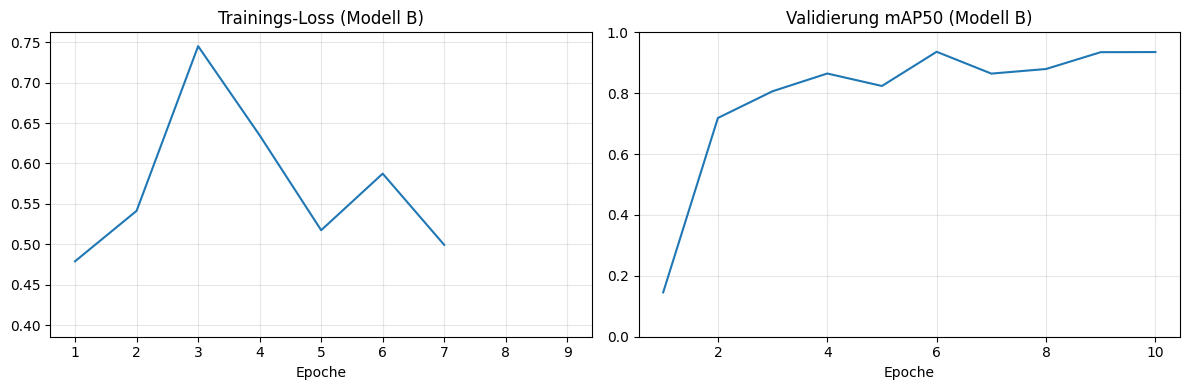

In [ ]:
h = hist_B
ep = [r['epoch'] for r in h]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, [r['loss'] for r in h])
axes[1].plot(ep, [r['val_map50'] for r in h])
axes[0].set(title='Trainings-Loss (Model C)', xlabel='Epoche')
axes[1].set(title='Validation with mAP50 (Model C)', xlabel='Epoche', ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'training_curves_C.png'), dpi=150)
plt.show()

In [ ]:
def draw(model, rec, conf=CONF, dust_m=0, dark=0):
    img, _ = CaveDataset([rec], dust_m=dust_m, dark=dark)[0]
    p = predict(model, img)
    keep = p['scores'] >= conf
    labels = [f"{class_names[l - 1]} {s:.2f}" for l, s in zip(p['labels'][keep], p['scores'][keep])]
    img_u8 = (img * 255).to(torch.uint8)
    out = draw_bounding_boxes(img_u8, p['boxes'][keep], labels=labels, colors='lime', width=2)
    return out.permute(1, 2, 0).numpy()


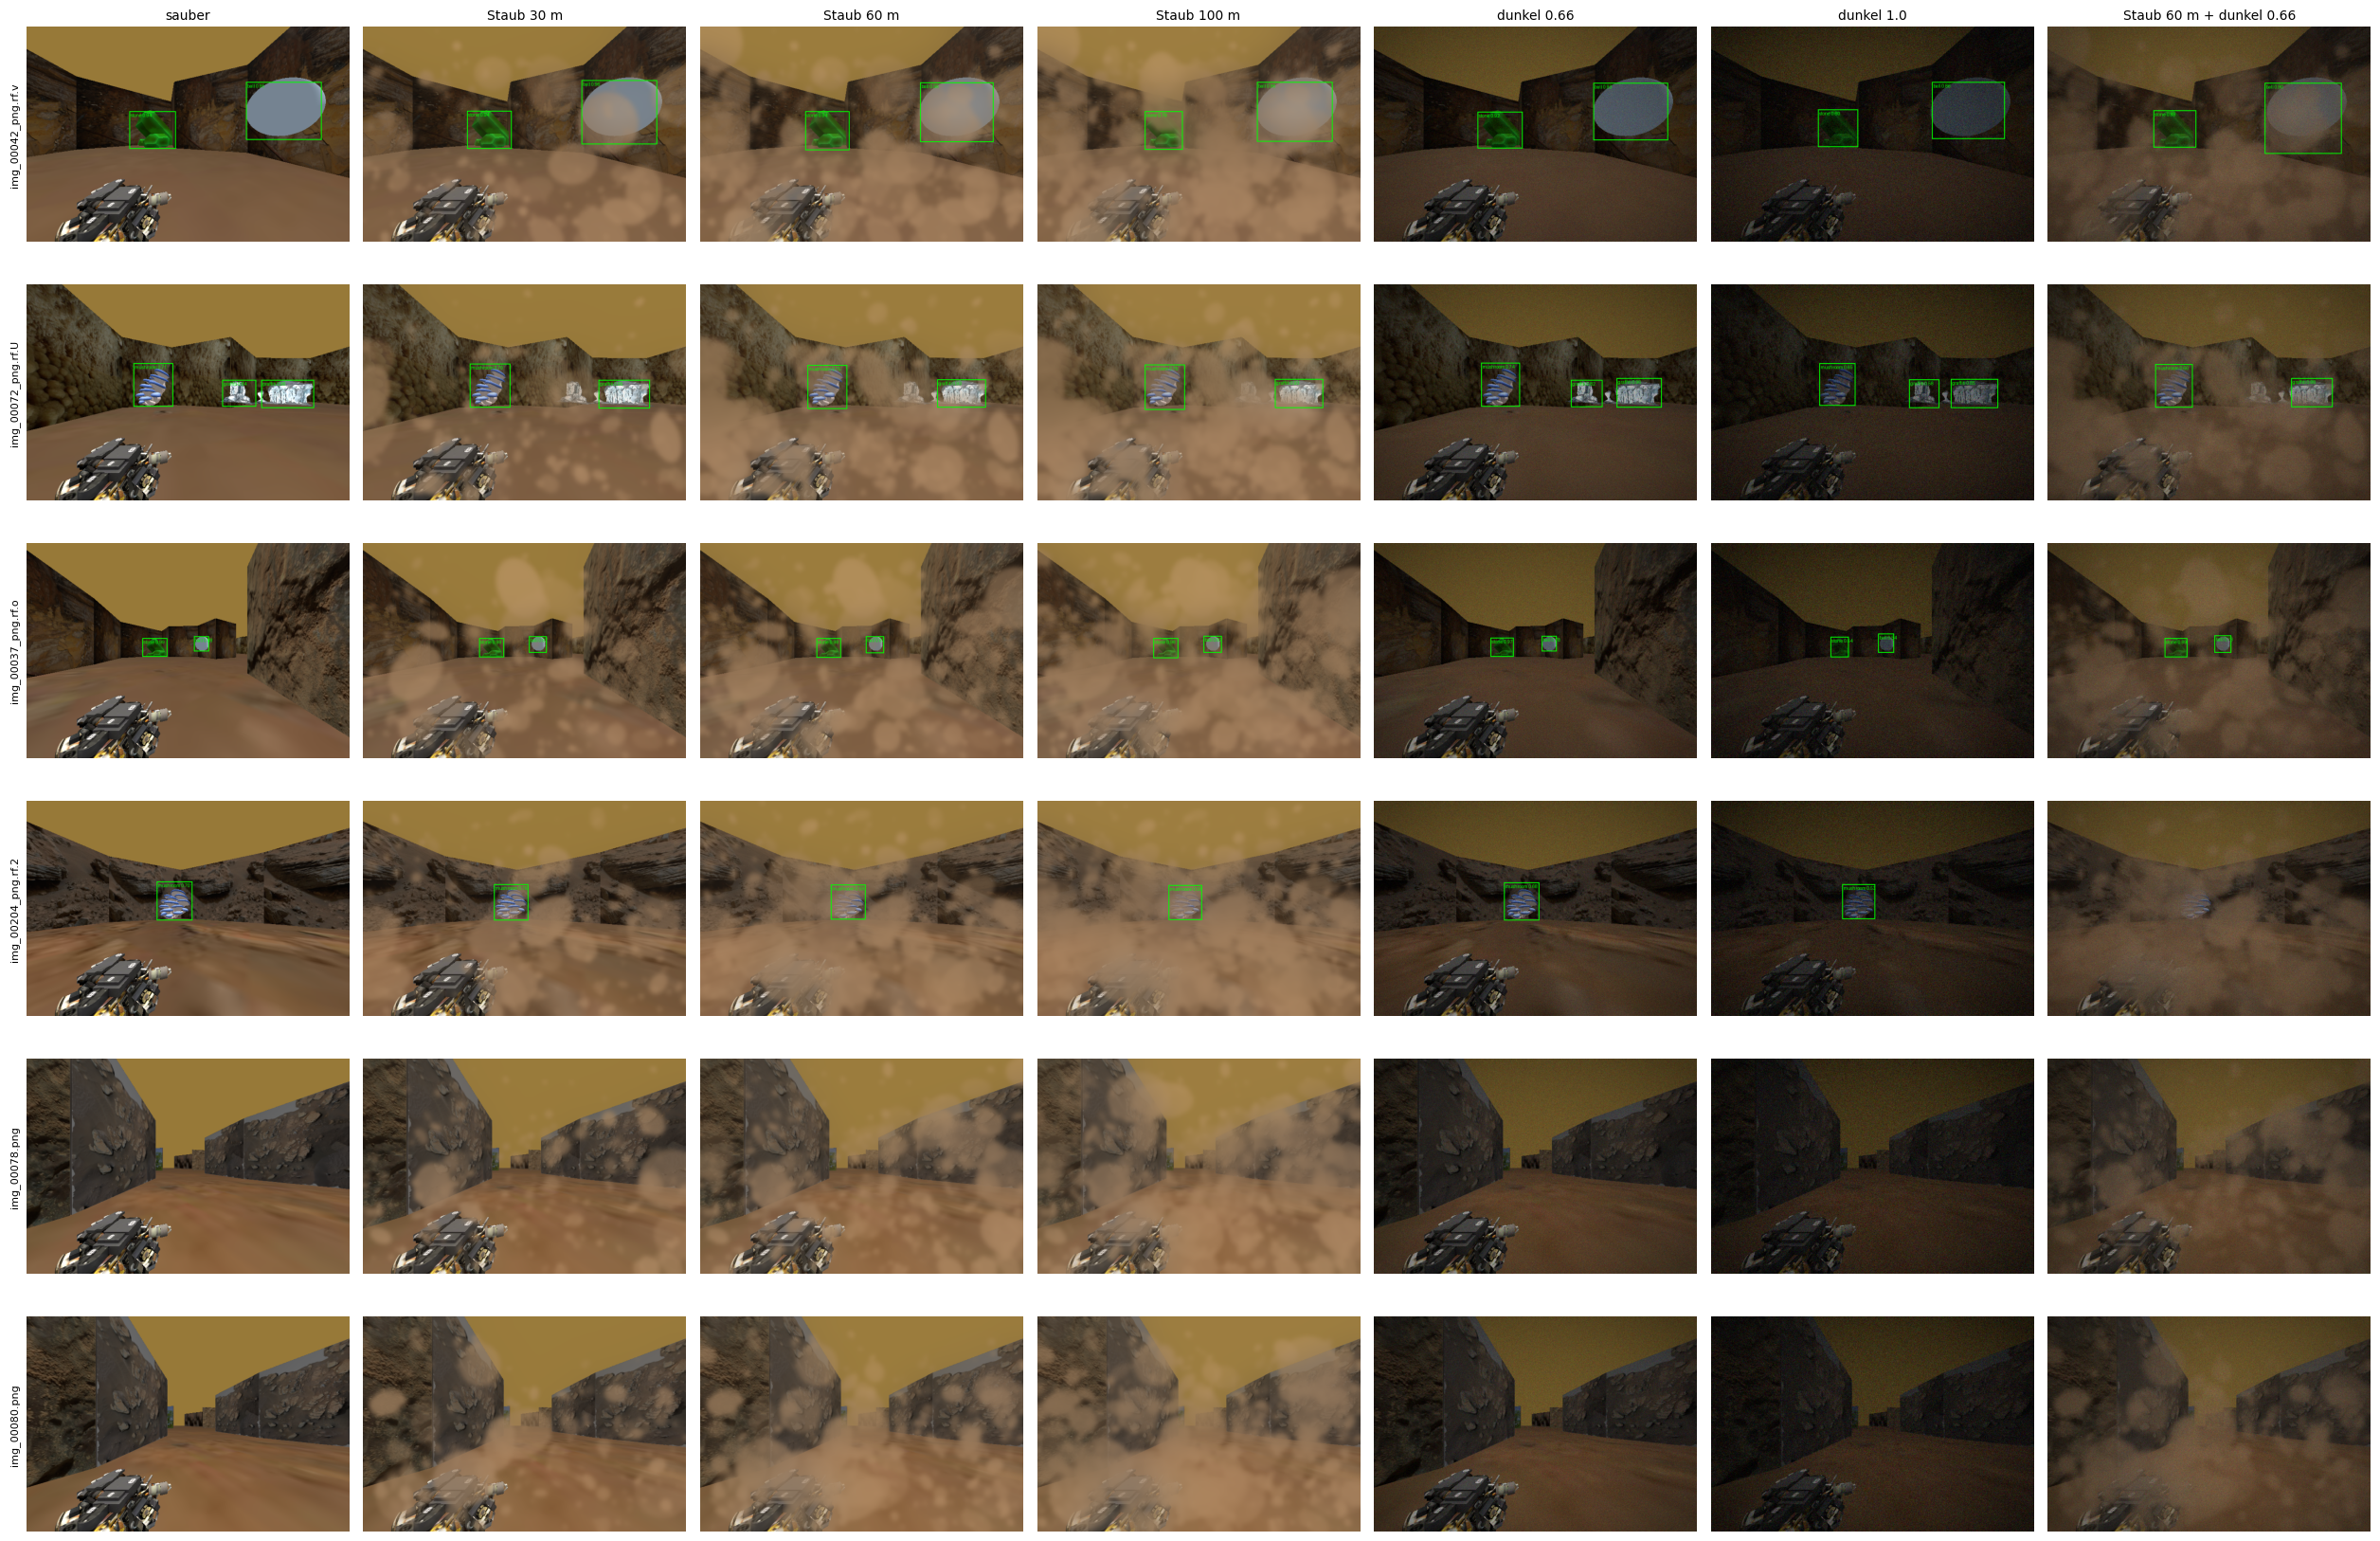

In [ ]:
conds = [('clean', {}),
         ('dust 30 m', {'dust_m': 30}),
         ('dust 60 m', {'dust_m': 60}),
         ('dust 100 m', {'dust_m': 100}),
         ('dark 0.66', {'dark': 0.66}),
         ('dark 1.0', {'dark': 1.0}),
         ('Staub 60 m + dunkel 0.66', {'dust_m': 60, 'dark': 0.66})]

random.seed(0)
samples = random.sample(test_records, min(4, len(test_records))) + neg_test[:2]

fig, axes = plt.subplots(len(samples), len(conds),
                         figsize=(3.6 * len(conds), 2.8 * len(samples)), squeeze=False)
for row, rec in zip(axes, samples):
    for ax, (tag, kw) in zip(row, conds):
        ax.imshow(draw(model_B, rec, **kw))
        ax.axis('off')
for ax, (tag, _) in zip(axes[0], conds):          
    ax.set_title(tag, fontsize=10)
for ax, rec in zip(axes[:, 0], samples):         
    ax.text(-0.02, 0.5, rec['name'][:18], transform=ax.transAxes,
            rotation=90, ha='right', va='center', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'examples_C_degraded.png'), dpi=120)
plt.show()